## Student Performance Indicator


#### Life cycle of Machine learning Project

- Understanding the Problem Statement
- Data Collection
- Data Checks to perform
- Exploratory data analysis
- Data Pre-Processing
- Model Training
- Choose best model

### 1) Problem statement
- This project understands how the student's performance (test scores) is affected by other variables such as Gender, Ethnicity, Parental level of education, Lunch and Test preparation course.


### 2) Data Collection
- Dataset Source - https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?datasetId=74977
- The data consists of 8 column and 1000 rows.

## **1. Environment Setup**

In [20]:
# Warning management and configuration
import warnings
warnings.filterwarnings('ignore')

# Data manipulation and numerical operations
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Enable inline plotting for Jupyter Notebooks
%matplotlib inline

## **2. Exploratoty Data Analysis**

### **2.1. Data Loading**

In [21]:
df = pd.read_csv('data/stud.csv')

### **2.2. Initial Data Inspection**

Before diving into visualizations, we need to inspect the data quality and ensure everything is clean. On that note, we'll check:

- Dataset structure
- Data types
- Missing values
- Unique values/categories per column
- Duplicate rows
- Dataset statistics

In [22]:
# Preview of the first observations
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [23]:
# Shape of the dataset
df.shape

(1000, 8)

In [24]:
# Basic information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [25]:
# Display unique categories for each categorical feature
print("Categories in 'gender':", df['gender'].unique().tolist())
print("Categories in 'race_ethnicity':", df['race_ethnicity'].unique().tolist())
print("Categories in 'parental_level_of_education':", df['parental_level_of_education'].unique().tolist())
print("Categories in 'lunch':", df['lunch'].unique().tolist())
print("Categories in 'test_preparation_course':", df['test_preparation_course'].unique().tolist())

Categories in 'gender': ['female', 'male']
Categories in 'race_ethnicity': ['group B', 'group C', 'group A', 'group D', 'group E']
Categories in 'parental_level_of_education': ["bachelor's degree", 'some college', "master's degree", "associate's degree", 'high school', 'some high school']
Categories in 'lunch': ['standard', 'free/reduced']
Categories in 'test_preparation_course': ['none', 'completed']


### **Dataset Information**

Dataset structure and features:

- `gender`: Student's gender (`male` / `female`).
- `race_ethnicity`: Ethnic group (`Group A`, `Group B`, `Group C`, `Group D`, `Group E`).
- `parental_level_of_education`: Parents' highest education level (`bachelor's degree`, `some college`, `master's degree`, `associate's degree`, `high school`, `some high school`).
- `lunch`: Type of lunch before the test (`standard` or `free/reduced`).
- `test_preparation_course`: Whether the student completed a prep course (`completed` or `none`).
- `math_score`: Score achieved in math.
- `reading_score`: Score achieved in reading.
- `writing_score`: Score achieved in writing.

### *Key findings*
As of **data types**, categorical features are stored cleanly as strings, while scores (`math`, `reading`, `writing`, `total score`, and `average`) are correctly typed as numeric (`int64` and `float64`). 

Also, we see there are no missing values, so we can proceed with our duplicates analysis.

### **Checking Duplicates**

In [26]:
# Check for duplicate rows in the dataset
print(f"Number of duplicate rows: {df.duplicated().sum()}")

Number of duplicate rows: 0


No duplicate rows found. Every record in our dataset is completely unique, so we don't need to drop anything.

### **Checking the number of unique values of each column**

In [27]:
# Check the number of unique values for each column
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

Inspected categorical features to confirm consistent labeling and verify that categories match expected values without hidden typos or formatting issues.

### **Checking statistics of dataset**

In [28]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


### *Key Findings*
- **Score Distribution**: Mean scores across all three subjects remain closely aligned around 66–69 points, with reading and writing showing slightly higher averages than mathematics.
- **Spread and Variability**: Standard deviations remain consistent near 14–15 points, indicating a uniform dispersion of student performance across subjects.
- **Extreme Values**: Minimum values reveal lower outliers (such as 0 in math and 10 in writing), while maximum values reach the absolute cap of 100 points across all categories.

In [29]:
# Define numerical and categorical features dynamically
numeric_features = df.select_dtypes(include=['number']).columns.tolist()
categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Display feature counts and lists
print(f"We have {len(numeric_features)} numerical features: {numeric_features}")
print(f"\nWe have {len(categorical_features)} categorical features: {categorical_features}")

We have 3 numerical features: ['math_score', 'reading_score', 'writing_score']

We have 5 categorical features: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


## **3. Scores Analysis** 
### **3.1. Feature Engineering: Adding columns for "Total Score" and "Average"**

I'll generate aggregate performance metrics (`total_score` and `average`) by combining individual subject scores to provide a holistic view of student academic achievement.

In [30]:
# Calculate total score and average score across the three academic subjects
df['total_score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['average'] = df['total_score'] / 3

# Display the first few rows to verify the newly engineered features
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


### **3.2. Extreme Score Analysis**

- **Ceiling and Floor Effects**: Identifying counts at the absolute boundaries (100 or <= 20) helps detect potential test difficulty skew or clustering at the limits of the grading scale.
- **Outlier and Risk Detection**: Tracking severe underperformance highlights vulnerable student segments that may require targeted academic intervention or support.
- **Data Integrity**: Verifying extreme values ensures that boundary scores are valid records rather than data entry anomalies or system errors.

In [31]:
# Count students achieving full marks (100) in each subject
math_full = (df['math_score'] == 100).sum()
reading_full = (df['reading_score'] == 100).sum()
writing_full = (df['writing_score'] == 100).sum()

print(f"Number of students with full marks in Math: {math_full}")
print(f"Number of students with full marks in Reading: {reading_full}")
print(f"Number of students with full marks in Writing: {writing_full}")

Number of students with full marks in Math: 7
Number of students with full marks in Reading: 17
Number of students with full marks in Writing: 14


In [32]:
# Count students scoring 20 or fewer points in each subject
math_less_20 = (df['math_score'] <= 20).sum()
reading_less_20 = (df['reading_score'] <= 20).sum()
writing_less_20 = (df['writing_score'] <= 20).sum()

print(f"\nNumber of students with 20 marks or less in Math: {math_less_20}")
print(f"Number of students with 20 marks or less in Reading: {reading_less_20}")
print(f"Number of students with 20 marks or less in Writing: {writing_less_20}")


Number of students with 20 marks or less in Math: 4
Number of students with 20 marks or less in Reading: 1
Number of students with 20 marks or less in Writing: 3


### *Key Findings*
- **Performance Extremes**: Language subjects (reading and writing) exhibit a higher concentration of top scores (17 and 14 students respectively) compared to mathematics (7 students).
- **Underperformance Scarcity**: Scores of 20 or below are extremely rare across the dataset (4 in math, 1 in reading, 3 in writing), confirming that severe underperformance is isolated to a tiny fraction of students.
- **Targeted Support Potential**: While not implemented in the current scope, these lower-scoring records could be segmented in future iterations across demographic and socioeconomic features to identify risk patterns and guide supplemental academic support.

## **4. Data Visualization**
### **4.1 Average Score Distribution**

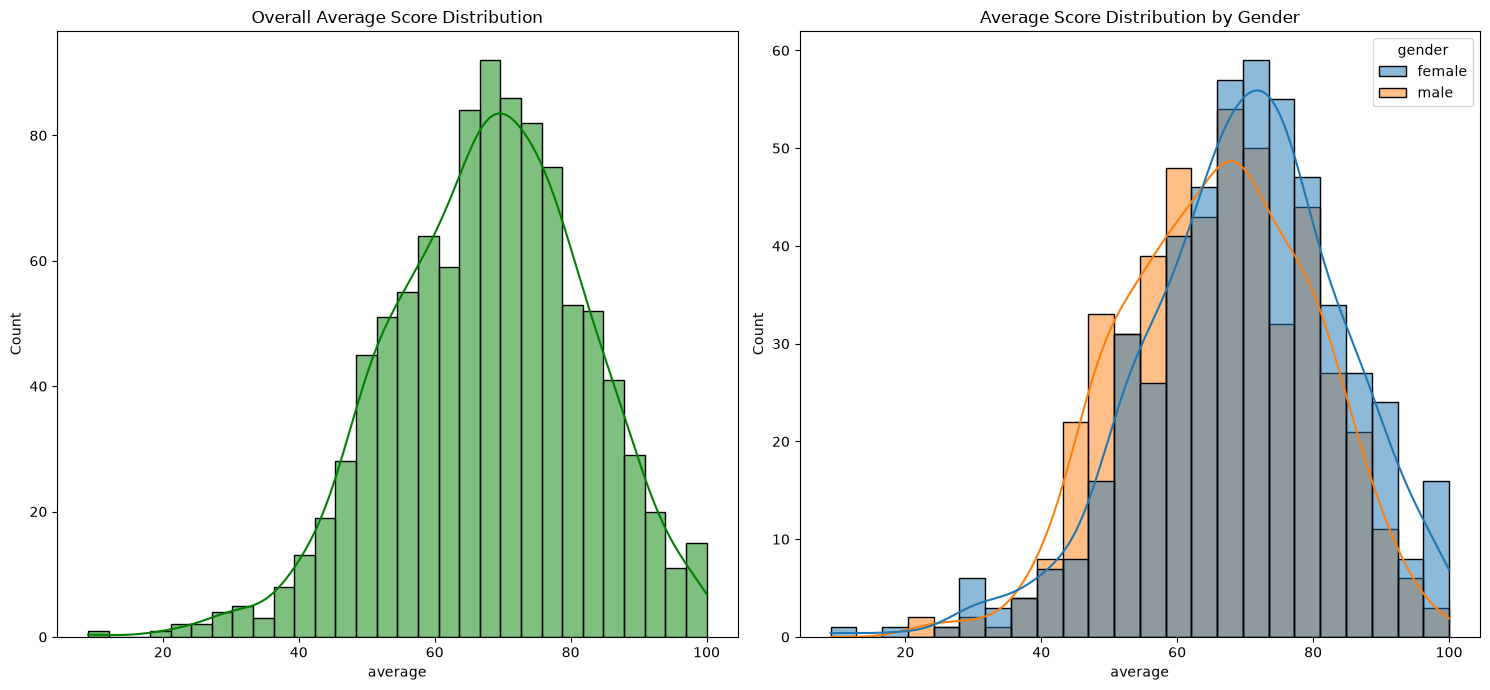

In [33]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))

# Plot 1: General distribution
sns.histplot(data=df, x='average', bins=30, kde=True, color='g', ax=axs[0])
axs[0].set_title('Overall Average Score Distribution')

# Plot 2: Distribution by gender
sns.histplot(data=df, x='average', kde=True, hue='gender', ax=axs[1])
axs[1].set_title('Average Score Distribution by Gender')

plt.tight_layout()
plt.show()

### *Key Findings*
- **Normal Distribution**: The overall average score distribution closely follows a bell-shaped normal curve, with the highest concentration of students clustering between 60 and 80 points.
- **Symmetric Spread**: The data exhibits a balanced dispersion centered around a mean of approximately 70, with very few extreme outliers on the lower and upper bounds.
- **Gender Performance Overlap**: When segmented by gender, both female and male score distributions share a similar central tendency, though female students show a slightly higher density in the upper-middle score ranges.

### **4.2 Maximumum Score Across Subjects**

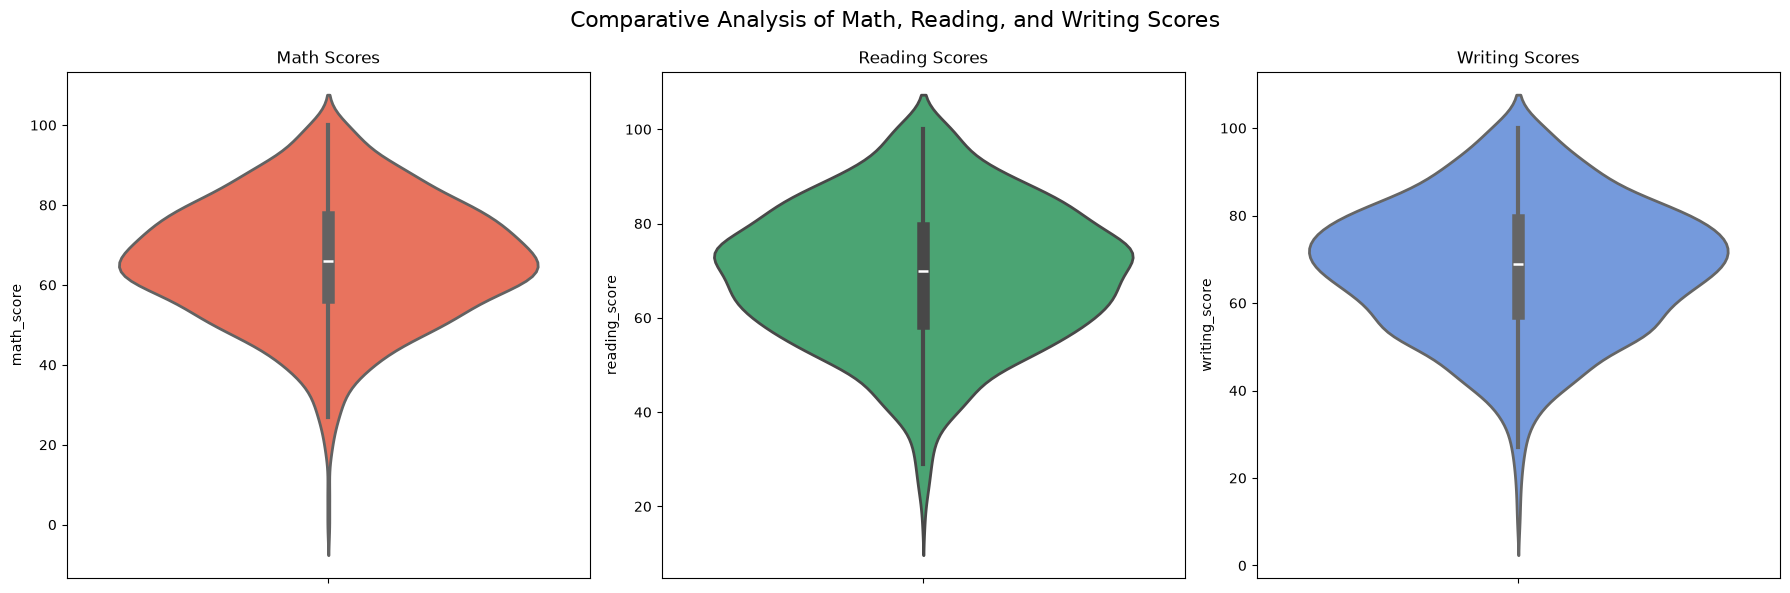

In [34]:
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

# Plot 1: Math scores distribution and variance
sns.violinplot(y='math_score', data=df, color='tomato', linewidth=2, ax=axs[0])
axs[0].set_title('Math Scores')

# Plot 2: Reading scores distribution and variance
sns.violinplot(y='reading_score', data=df, color='mediumseagreen', linewidth=2, ax=axs[1])
axs[1].set_title('Reading Scores')

# Plot 3: Writing scores distribution and variance
sns.violinplot(y='writing_score', data=df, color='cornflowerblue', linewidth=2, ax=axs[2])
axs[2].set_title('Writing Scores')

plt.suptitle('Comparative Analysis of Math, Reading, and Writing Scores', fontsize=16)
plt.tight_layout()
plt.show()

### *Key Findings*
- **Density Concentration**: All three subjects display bell-shaped kernel density estimates centered tightly between 60 and 80 points, indicating consistent central tendencies across disciplines.
- **Interquartile Range Symmetry**: The embedded box plots reveal uniform interquartile ranges (IQR) spanning roughly from 57 to 79 points across math, reading, and writing scores.
- **Lower Tail Dispersal**: Math scores exhibit a wider and more extended lower tail stretching down toward zero, whereas reading and writing show denser concentrations in their lower bounds without dipping as steeply.

### **4.3 Overall Demographic and Categorical Distribution**

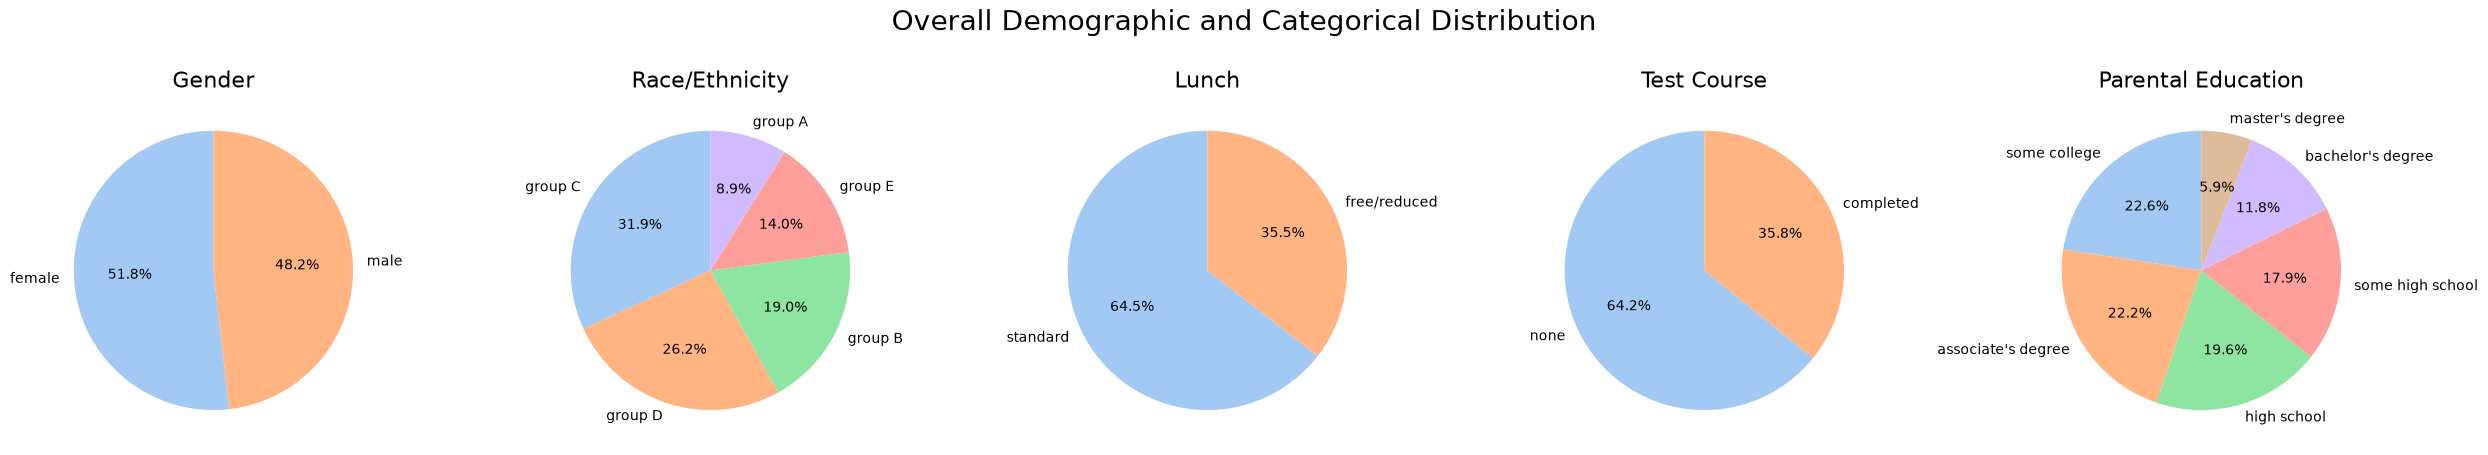

In [35]:
fig, axs = plt.subplots(1, 5, figsize=(25, 5))

# Plot 1: Gender distribution
gender_counts = df['gender'].value_counts()
axs[0].pie(gender_counts, labels=gender_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[0].set_title('Gender', fontsize=16)

# Plot 2: Race/Ethnicity distribution
race_counts = df['race_ethnicity'].value_counts()
axs[1].pie(race_counts, labels=race_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[1].set_title('Race/Ethnicity', fontsize=16)

# Plot 3: Lunch type distribution
lunch_counts = df['lunch'].value_counts()
axs[2].pie(lunch_counts, labels=lunch_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[2].set_title('Lunch', fontsize=16)

# Plot 4: Test preparation course status
prep_counts = df['test_preparation_course'].value_counts()
axs[3].pie(prep_counts, labels=prep_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[3].set_title('Test Course', fontsize=16)

# Plot 5: Parental level of education distribution
edu_counts = df['parental_level_of_education'].value_counts()
axs[4].pie(edu_counts, labels=edu_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[4].set_title('Parental Education', fontsize=16)

plt.suptitle('Overall Demographic and Categorical Distribution', fontsize=20)
plt.tight_layout()
plt.show()

### *Key Insights*
- **Demographic Balance**: Gender distribution remains relatively even (51.8% female and 48.2% male), while race/ethnicity shows Group C as the largest segment (31.9%) and Group A as the smallest (8.9%).
- **Socioeconomic and Preparation Split**: Standard lunch accounts for the majority at 64.5% compared to 35.5% for free/reduced, and a similar proportion (64.2%) of students did not complete the test preparation course. It is yet to be seen if they're correlated.
- **Parental Education Diversity**: Parental education levels are well-distributed across categories, with "some college" (22.6%) and "associate's degree" (22.2%) forming the largest combined shares, while master's degrees represent the smallest group (5.9%).

### **4.4 Feature Relationships and Performance Impact**
#### **4.4.1 GENDER COLUMN**

How does gender impact on student's performance?

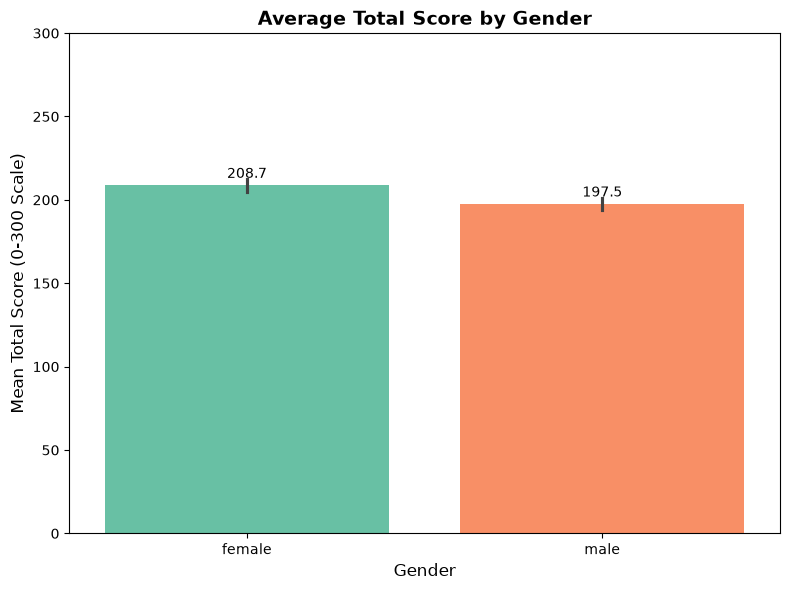

In [36]:
# Set up the figure for total score
fig, ax = plt.subplots(figsize=(8, 6))

# Plot bar chart for total score grouped by gender
sns.barplot(
    data=df,
    x='gender',
    y='total_score',
    hue='gender',
    palette='Set2',
    ax=ax,
    saturation=0.95
)

# Configure titles, labels, and scale
ax.set_title('Average Total Score by Gender', fontsize=14, fontweight='bold')
ax.set_xlabel('Gender', fontsize=12)
ax.set_ylabel('Mean Total Score (0-300 Scale)', fontsize=12)
ax.set_ylim(0, 300)

# Add value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

# Remove redundant legend if x-axis already displays gender
ax.legend().set_visible(False)
plt.tight_layout()
plt.show()

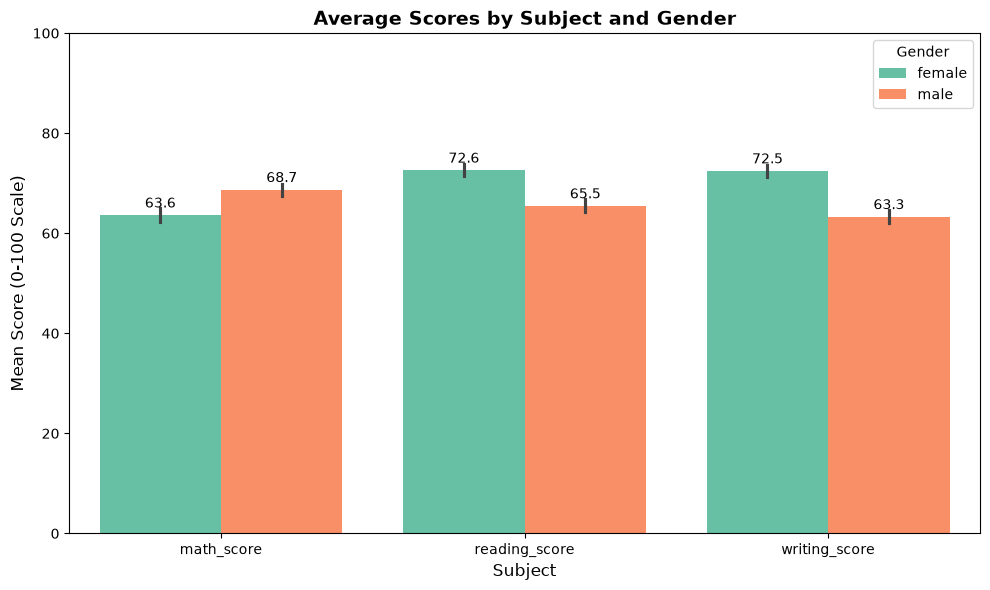

In [37]:
# Prepare data for individual subject scores
score_cols_ind = ['gender', 'math_score', 'reading_score', 'writing_score']
df_ind_long = df[score_cols_ind].melt(id_vars='gender', var_name='subject', value_name='score')

# Set up the figure
fig, ax = plt.subplots(figsize=(10, 6))

# Plot bar chart for individual subjects
sns.barplot(
    data=df_ind_long,
    x='subject',
    y='score',
    hue='gender',
    palette='Set2',
    ax=ax,
    saturation=0.95
)

# Configure titles, labels, and scale
ax.set_title('Average Scores by Subject and Gender', fontsize=14, fontweight='bold')
ax.set_xlabel('Subject', fontsize=12)
ax.set_ylabel('Mean Score (0-100 Scale)', fontsize=12)
ax.set_ylim(0, 100)

# Add value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

ax.legend(title='Gender', loc='upper right')
plt.tight_layout()
plt.show()

### *Key Findings*
- **Subject-Specific Performance Divergence**: Male students achieve a higher average score in mathematics (68.7 vs 63.6), whereas female students outperform males in reading (72.6 vs 65.5) and writing (72.5 vs 63.3).
- **Aggregate Total Score Advantage**: Driven primarily by their stronger performance in language and literacy subjects, female students record a higher average total score overall (208.7) compared to male students (197.5).
- **Performance Trade-Off**: The comparison demonstrates a clear domain-specific performance split between genders, highlighting mathematics as a relative strength for male students and language arts as a relative strength for female students.

#### **4.4.2 RACE/ETHNICITY**

- How do academic scores vary across different racial/ethnic groups?

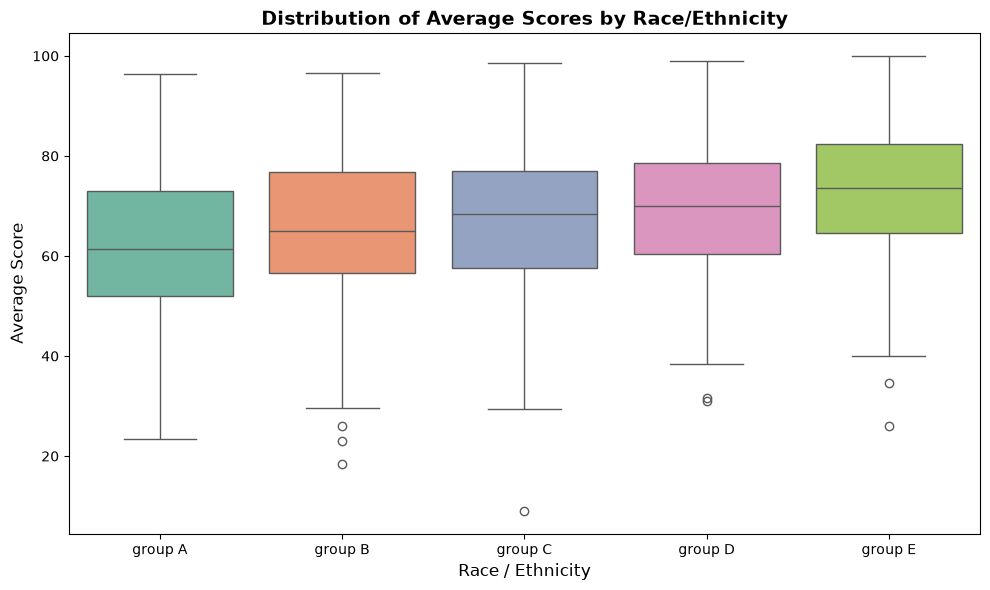

In [51]:
race_order = ['group A', 'group B', 'group C', 'group D', 'group E']

# Create a consistent color mapping for each race/ethnicity group across all plots
categories = sorted(df['race_ethnicity'].dropna().unique())
color_palette = sns.color_palette('Set2', len(categories))
palette_dict = dict(zip(categories, color_palette))

fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='race_ethnicity',
    y='average',
    order=race_order,
    palette=palette_dict,
    ax=ax
)

ax.set_title('Distribution of Average Scores by Race/Ethnicity', fontsize=14, fontweight='bold')
ax.set_xlabel('Race / Ethnicity', fontsize=12)
ax.set_ylabel('Average Score', fontsize=12)

plt.tight_layout()
plt.show()

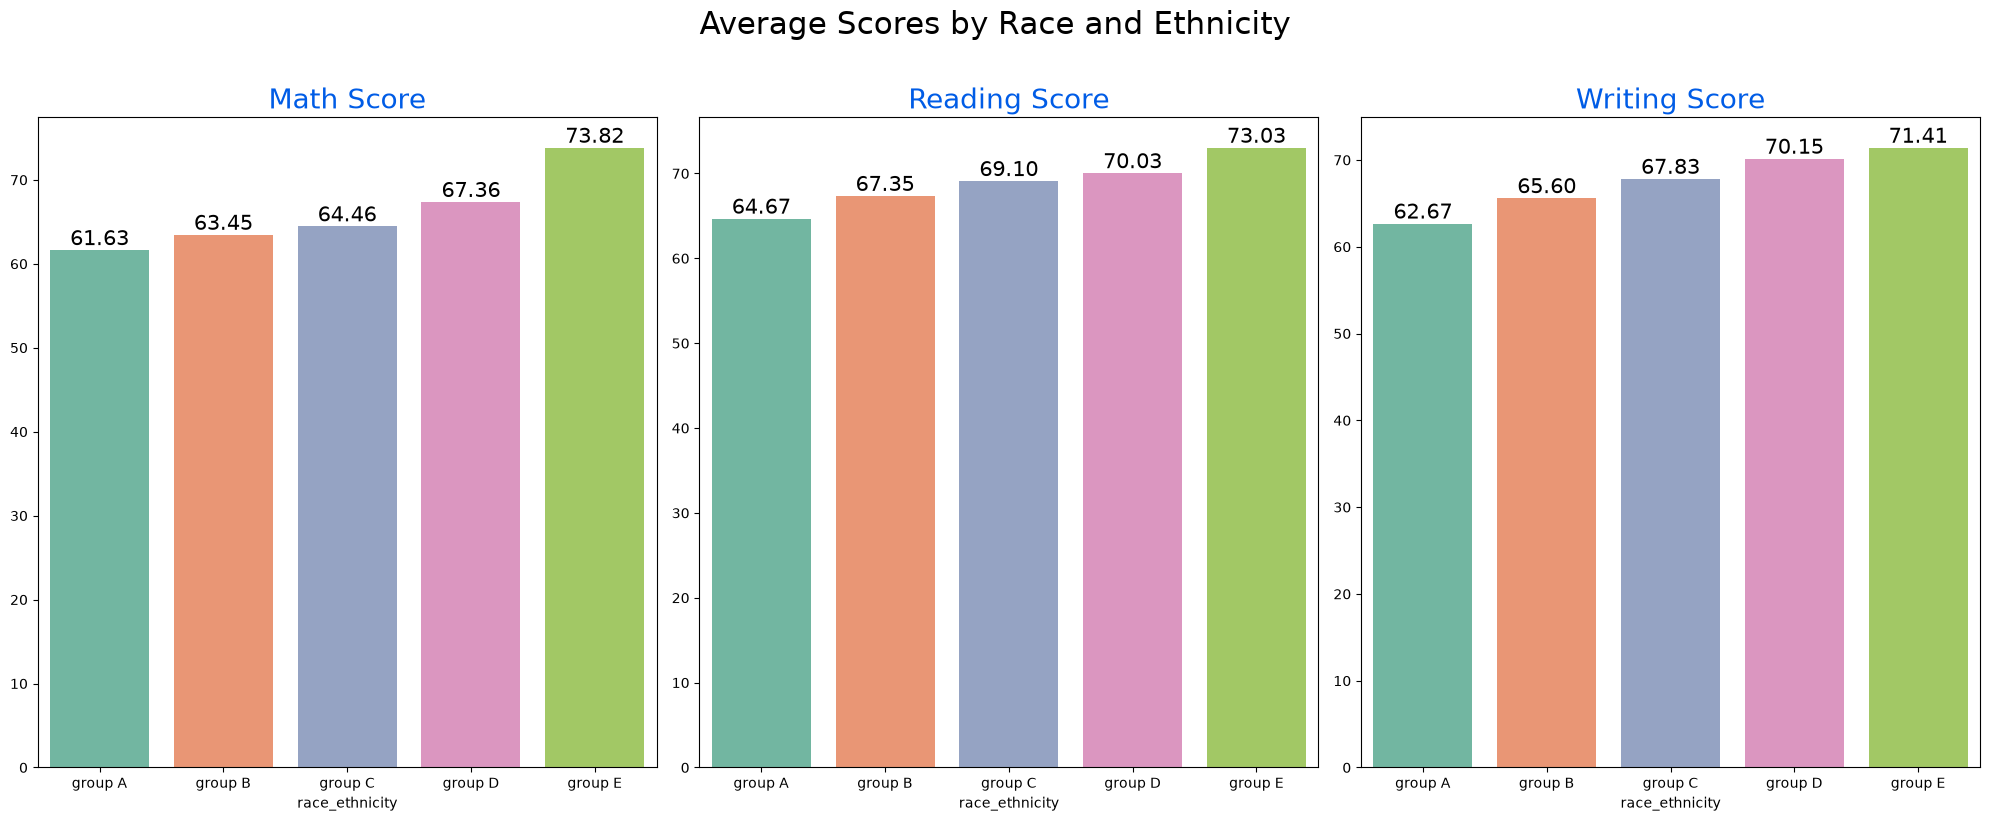

In [ ]:
# Group data by race/ethnicity
group_data2 = df.groupby('race_ethnicity')

fig, axs = plt.subplots(1, 3, figsize=(20, 8))

# Plot 1: Math score mean by race/ethnicity
sns.barplot(
    x=group_data2['math_score'].mean().index, 
    y=group_data2['math_score'].mean().values, 
    hue=group_data2['math_score'].mean().index,
    palette=palette_dict, 
    legend=False,
    ax=axs[0]
)
axs[0].set_title('Math Score', color='#005ce6', size=20)
for container in axs[0].containers:
    axs[0].bar_label(container, color='black', size=15, fmt='%.2f')

# Plot 2: Reading score mean by race/ethnicity
sns.barplot(
    x=group_data2['reading_score'].mean().index, 
    y=group_data2['reading_score'].mean().values, 
    hue=group_data2['reading_score'].mean().index,
    palette=palette_dict, 
    legend=False,
    ax=axs[1]
)
axs[1].set_title('Reading Score', color='#005ce6', size=20)
for container in axs[1].containers:
    axs[1].bar_label(container, color='black', size=15, fmt='%.2f')

# Plot 3: Writing score mean by race/ethnicity
sns.barplot(
    x=group_data2['writing_score'].mean().index, 
    y=group_data2['writing_score'].mean().values, 
    hue=group_data2['writing_score'].mean().index,
    palette=palette_dict, 
    legend=False,
    ax=axs[2]
)
axs[2].set_title('Writing Score', color='#005ce6', size=20)
for container in axs[2].containers:
    axs[2].bar_label(container, color='black', size=15, fmt='%.2f')

plt.suptitle('Average Scores by Race and Ethnicity', fontsize=22, y=1.02)
plt.tight_layout()
plt.show()

### *Key Findings*
- **Cross-Subject Uniformity & Medians**: The relative performance hierarchy remains identical, while the median average scores (represented by the central lines) show a clear upward progression from Group A up to Group E.
- **Consistent Performance Extremes**: Group E consistently achieves the highest performance levels across the board (math: 73.82, reading: 73.03, writing: 71.41) alongside the highest median and upper quartile thresholds, while Group A records the lowest overall averages and median scores.
- **Distribution Spread and Outliers**: The box plots reveal that while higher-performing groups like Group D and E shift upward in their overall distributions, groups B and C contain lower-bound outliers representing students with greater academic difficulties.

#### **4.4.3 PARENTAL LEVEL OF EDUCATION**

- Does parental education level have a measurable impact on student performance?

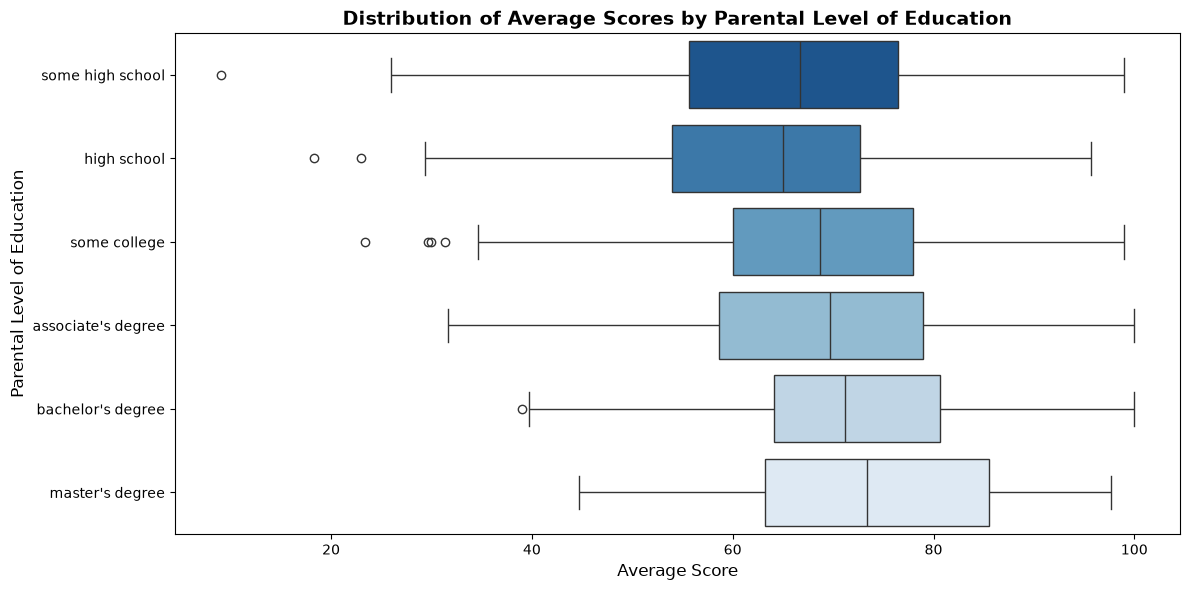

In [ ]:
# Define the logical hierarchical order from lowest to highest level of education
education_order = [
    'some high school',
    'high school',
    'some college',
    "associate's degree",
    "bachelor's degree",
    "master's degree"
]

fig, ax = plt.subplots(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='average',
    y='parental_level_of_education',
    order=education_order,
    palette='Blues_r',
    ax=ax
)

ax.set_title('Distribution of Average Scores by Parental Level of Education', fontsize=14, fontweight='bold')
ax.set_xlabel('Average Score', fontsize=12)
ax.set_ylabel('Parental Level of Education', fontsize=12)

plt.tight_layout()
plt.show()

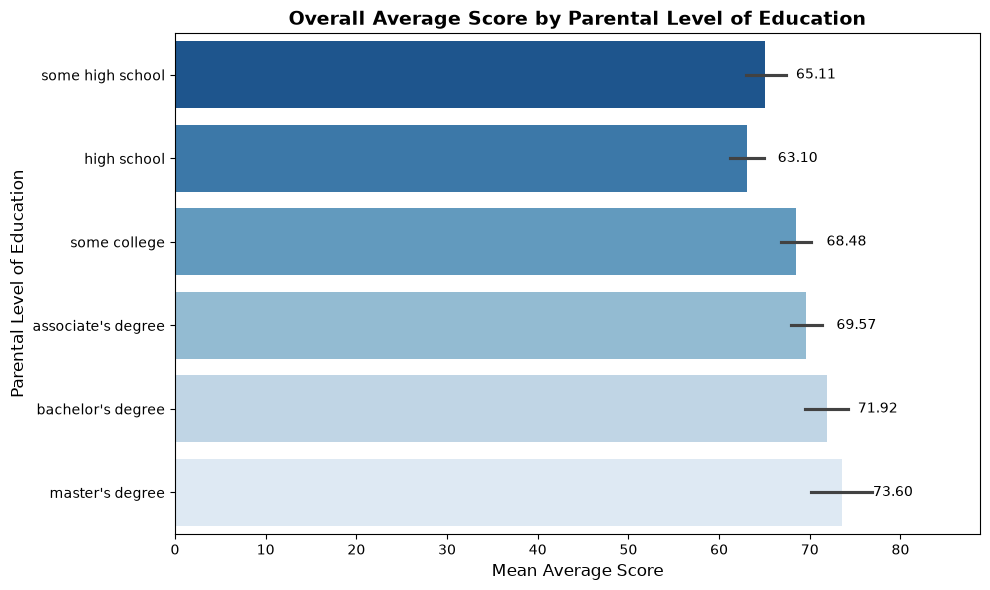

In [45]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=df,
    y='parental_level_of_education',
    x='average',
    order=education_order,
    palette='Blues_r',
    ax=ax
)

ax.set_title('Overall Average Score by Parental Level of Education', fontsize=14, fontweight='bold')
ax.set_xlabel('Mean Average Score', fontsize=12)
ax.set_ylabel('Parental Level of Education', fontsize=12)
ax.set_xlim(0, ax.get_xlim()[1] * 1.1)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=22)


plt.tight_layout()
plt.show()

### *Key Findings*
* **Educational Attainment Gradient**: Student average scores and median values increase progressively with higher levels of parental education, with master's and bachelor's degrees yielding the highest overall standing (73.60 and 71.92 mean respectively).

* **Distribution Variability & Outliers**: Lower education levels feature wider dispersions with lower-bound outliers and high maximum scores reaching near 100, whereas higher tiers like master's degrees show more constrained ranges where scores don't drop below 40 or reach absolute maximums.

* **Resilience Across Backgrounds**: Despite the general performance trend linked to parental education, highly promising high-performing students appear across practically all educational tiers.

#### **4.4.4 LUNCH COLUMN**
- What is the effect of lunch type on test results?

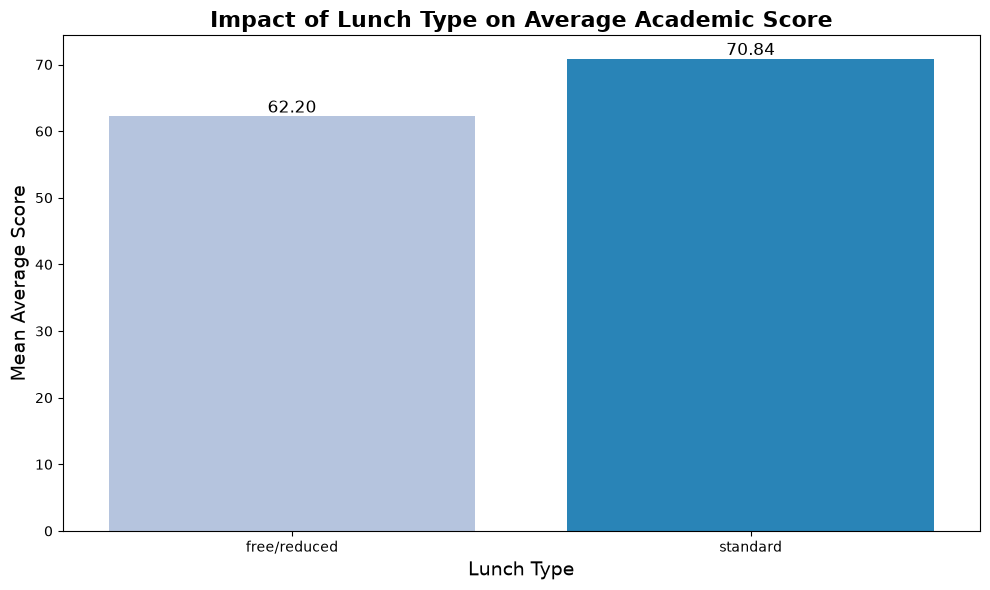

In [46]:
# Group data by lunch type and compute the mean of the average score
lunch_group = df.groupby('lunch')['average'].mean().reset_index()

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Plot bar chart for lunch type vs average score
sns.barplot(
    data=lunch_group,
    x='lunch',
    y='average',
    hue='lunch',
    palette='PuBu',
    legend=False,
    ax=ax,
    saturation=0.95
)

# Configure titles and labels
ax.set_title('Impact of Lunch Type on Average Academic Score', fontsize=16, fontweight='bold')
ax.set_xlabel('Lunch Type', fontsize=14)
ax.set_ylabel('Mean Average Score', fontsize=14)

# Add value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, color='black', size=12, fmt='%.2f')

plt.tight_layout()
plt.show()

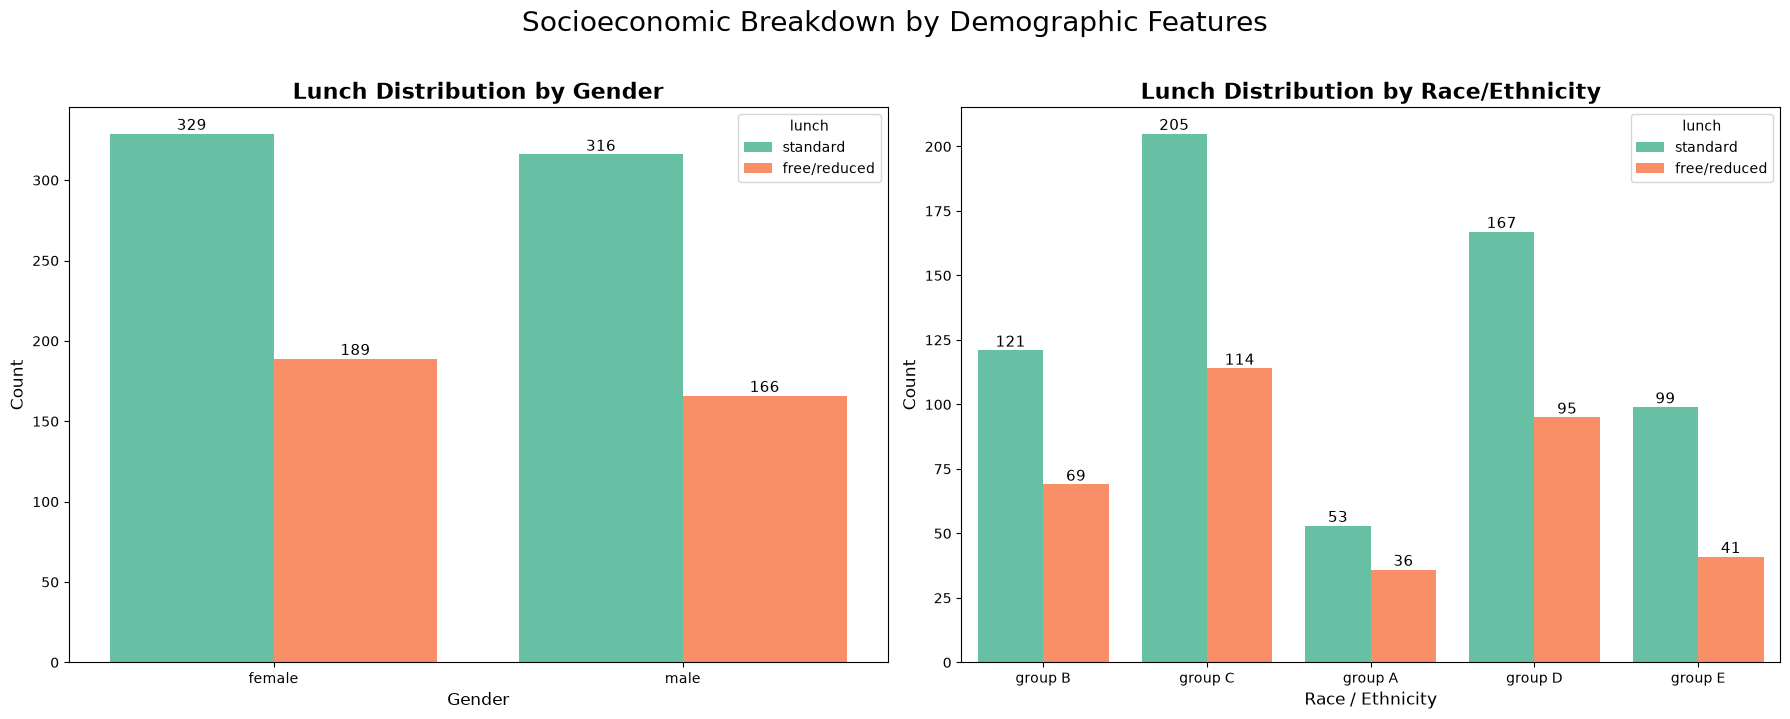

In [47]:
fig, axs = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: Lunch distribution across genders
sns.countplot(
    data=df,
    x='gender',
    hue='lunch',
    palette='Set2',
    ax=axs[0],
    saturation=0.95
)
axs[0].set_title('Lunch Distribution by Gender', fontsize=16, fontweight='bold')
axs[0].set_xlabel('Gender', fontsize=12)
axs[0].set_ylabel('Count', fontsize=12)
for container in axs[0].containers:
    axs[0].bar_label(container, color='black', size=11)

# Plot 2: Lunch distribution across race/ethnicity
sns.countplot(
    data=df,
    x='race_ethnicity',
    hue='lunch',
    palette='Set2',
    ax=axs[1],
    saturation=0.95
)
axs[1].set_title('Lunch Distribution by Race/Ethnicity', fontsize=16, fontweight='bold')
axs[1].set_xlabel('Race / Ethnicity', fontsize=12)
axs[1].set_ylabel('Count', fontsize=12)
for container in axs[1].containers:
    axs[1].bar_label(container, color='black', size=11)

plt.suptitle('Socioeconomic Breakdown by Demographic Features', fontsize=20, y=1.02)
plt.tight_layout()
plt.show()

### *Key Findings*
- **Significant Performance Gap**: Students with standard lunch type achieve a notably higher mean average score (70.84) compared to those with free/reduced lunch (62.20).
- **Socioeconomic Impact**: Lunch type serves as a strong indicator of academic performance, reflecting a clear performance advantage associated with standard socioeconomic status.
- **Demographic Distribution Consistency**: Standard lunch represents the majority across all gender and ethnic groups, with Group C and female students showing the highest absolute counts for both lunch categories.

#### **4.4.5 TEST PREPARATION COURSE COLUMN**
- Does the completion of the test prepration course have any impact on student's performance?

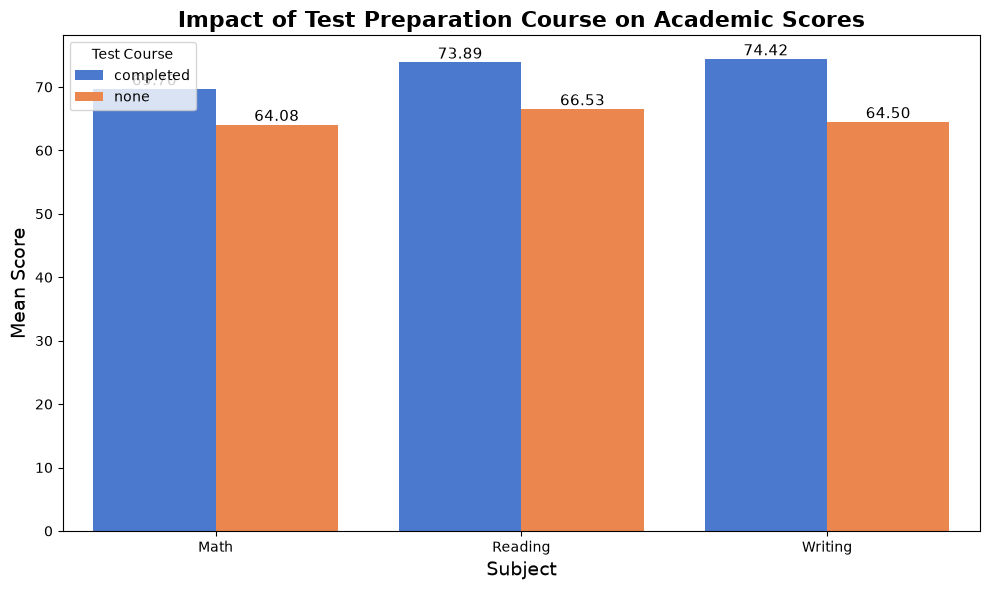

In [48]:
# Group by test preparation course and compute the mean of the score categories
prep_group = df.groupby('test_preparation_course')[['math_score', 'reading_score', 'writing_score']].mean().reset_index()

# Melt the dataframe from wide to long format for Seaborn barplot
prep_melted = prep_group.melt(
    id_vars='test_preparation_course', 
    value_vars=['math_score', 'reading_score', 'writing_score'],
    var_name='subject', 
    value_name='mean_score'
)

# Clean up subject names for better readability in the legend/axis
prep_melted['subject'] = prep_melted['subject'].str.replace('_score', '').str.capitalize()

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Plot grouped bar chart comparing scores across subjects by test preparation status
sns.barplot(
    data=prep_melted,
    x='subject',
    y='mean_score',
    hue='test_preparation_course',
    palette='muted',
    ax=ax,
    saturation=0.95
)

# Configure titles, labels, and legend
ax.set_title('Impact of Test Preparation Course on Academic Scores', fontsize=16, fontweight='bold')
ax.set_xlabel('Subject', fontsize=14)
ax.set_ylabel('Mean Score', fontsize=14)
ax.legend(title='Test Course', loc='upper left')

# Add value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, color='black', size=11, fmt='%.2f')

plt.tight_layout()
plt.show()

### *Key Findings*
- **Consistent Performance Advantage**: Students who completed the test preparation course consistently achieve higher mean scores across all three subjects (Math: 69.70 vs 64.08, Reading: 73.89 vs 66.53, Writing: 74.42 vs 64.50). Therefore, the course proves to be an effective academic intervention.
- **Pronounced Writing Gains**: The largest performance gap driven by test preparation occurs in the writing section, where students with completed courses outperform those without by nearly 10 points.

#### **4.4.6 MUTIVARIATE ANALYSIS USING PAIRPLOT**

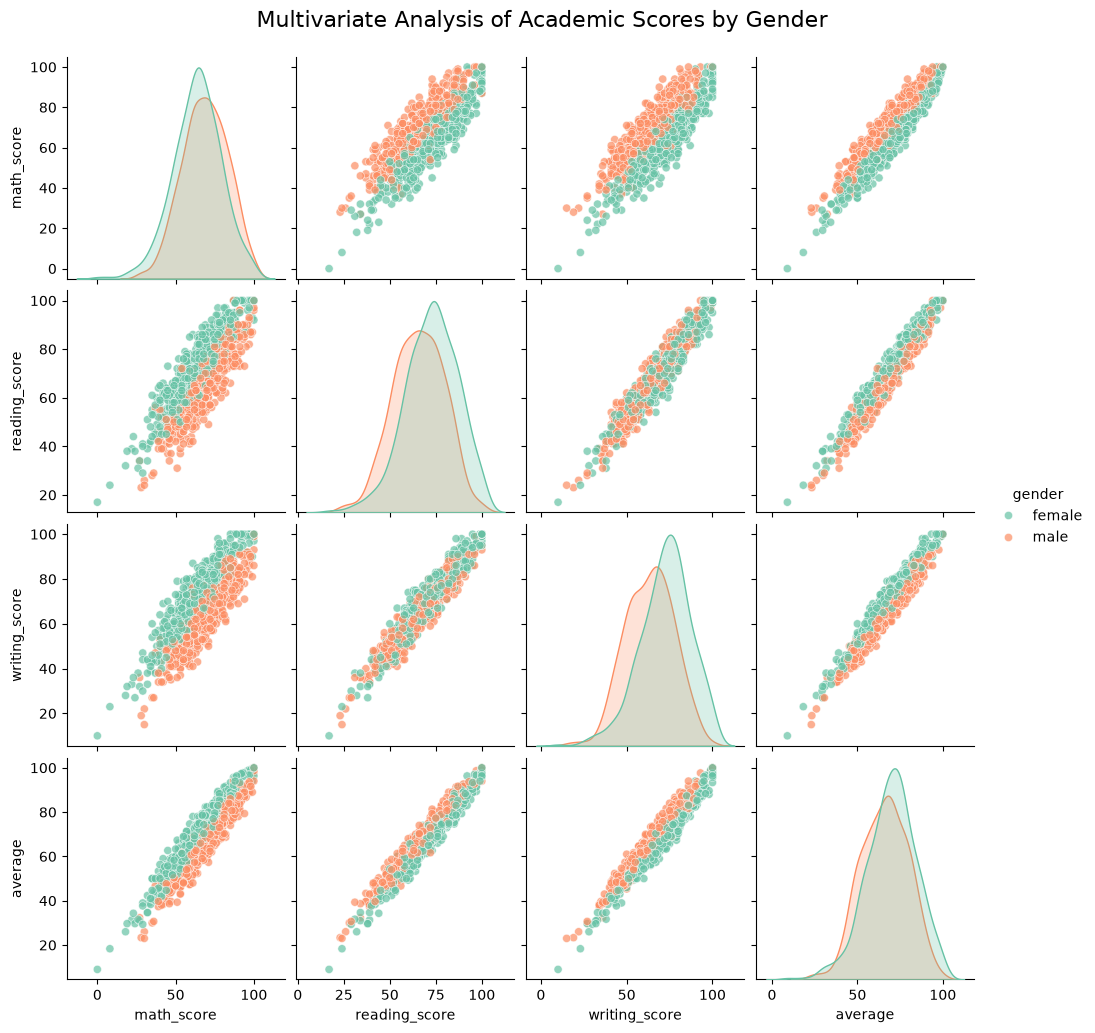

In [49]:
# Create a pairplot for multivariate analysis colored by gender
# We explicitly select the numerical score columns and 'gender' to keep it clean and performant
score_columns = ['math_score', 'reading_score', 'writing_score', 'average', 'gender']

pair_plot = sns.pairplot(
    data=df[score_columns], 
    hue='gender', 
    palette='Set2', 
    diag_kind='kde',
    plot_kws={'alpha': 0.7, 's': 35},
    height=2.5
)

# Grid title
pair_plot.fig.suptitle('Multivariate Analysis of Academic Scores by Gender', fontsize=16, y=1.03)

plt.show()

### *Key Findings*

* **Strong Linear Inter-Subject Correlation**: The scatter plots between reading, writing, and math demonstrate strong positive linearity, showing that students who excel in one academic area tend to score proportionally high across the others.
* **Gender Clustering in Extremes**: In the math versus reading/writing scatter plots, female data points (green) dominate the upper-right region for literacy, while male data points (orange) push further into the upper bounds of the math spectrum.
* **Distribution Symmetry**: The diagonal KDE curves confirm that overall average scores closely mirror normal distributions for both genders, with female density curves shifted slightly toward higher score thresholds.

## **5. Conclusions**
* **Socioeconomic and Institutional Impact**: Academic performance is heavily shaped by structural factors, with parental education, socioeconomic indicators like lunch type, and preparatory courses creating significant performance gaps.
* **Domain-Specific Patterns**: Gender analysis reveals distinct disciplinary strengths, showing a male advantage in mathematics and a female advantage in reading and writing.
* **Individual Resilience and Potential**: Despite clear group-level trends and performance hierarchies, the presence of top-performing students across diverse educational and socioeconomic backgrounds highlights individual resilience and varied pathways to success.